# Palette Forge: a tiny demo 🎨
**Idea:** take a famous painting from a free museum API, let **machine learning** find its main colors, and use those colors
to paint a mock game screen.

```
Museum API ──▶ painting (JPG) ──▶ K-means (ML) ──▶ 5 colors ──▶ mock game screen (PNG)
```

| Step | What happens | Tool |
|---|---|---|
| 1 | Search a **CC0 (public-domain)** artwork | Cleveland Museum of Art Open Access API (free, no key) |
| 2 | Download the image | `requests` |
| 3 | Turn pixels into numbers and **group similar colors** | scikit-learn `KMeans` |
| 4 | Pick roles: dark, light, accent | simple rules (luminance, saturation) |
| 5 | Draw a swatch + a mock game screen | Pillow |

## Step 0 – Setup

In [1]:
import io
import colorsys
from pathlib import Path

import numpy as np
import requests
from PIL import Image, ImageDraw, ImageFont
from sklearn.cluster import KMeans
from IPython.display import display

# Corporate networks with HTTPS inspection: use the Windows certificate store if truststore is installed
try:
    import truststore
    truststore.inject_into_ssl()
except ImportError:
    pass

CMA = "https://openaccess-api.clevelandart.org/api/artworks/"
OUT = Path.cwd()
print("ready")

ready


## Step 1 – Find a CC0 artwork
The Cleveland Museum of Art publishes its collection through a free **Open Access API**. One request returns the details *and* the
image links. We filter with `cc0=1` and `has_image=1`, but **we never trust a filter blindly**: the loop checks the license field
(`share_license_status == "CC0"`) again on every record before using its image.

In [2]:
QUERY = "japanese woodblock"      # try: "water lilies", "sunset", "poppies", "stained glass", "peacock"

response = requests.get(CMA, params={"q": QUERY, "has_image": 1, "cc0": 1, "limit": 10,
                                     "fields": "id,title,creation_date,creators,images,share_license_status"}, timeout=30)
response.raise_for_status()
results = response.json()["data"]
print("results on this page:", len(results))

art = None
for record in results:
    web = (record.get("images") or {}).get("web") or {}
    if record.get("share_license_status") == "CC0" and web.get("url"):
        art = {"title": record["title"],
               "artist": (record.get("creators") or [{}])[0].get("description", "unknown artist"),
               "date": record.get("creation_date", ""),
               "image_url": web["url"]}
        break

print(art["title"], "|", art["artist"], "|", art["date"])
print("image:", art["image_url"])

results on this page: 10
South Wind, Clear Sky, from Thirty-Six Views of Mount Fuji | Katsushika Hokusai (Japanese, 1760–1849) | early 1830s
image: https://openaccess-cdn.clevelandart.org/1930.189/1930.189_web.jpg


## Step 2 – Download the image

size: (900, 617)


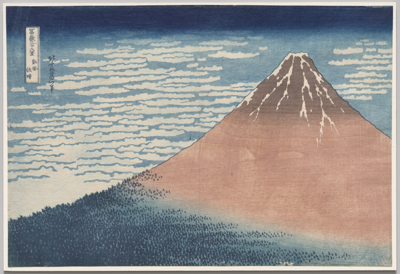

In [3]:
img = Image.open(io.BytesIO(requests.get(art["image_url"], timeout=30).content)).convert("RGB")
print("size:", img.size)
display(img.resize((400, int(400 * img.height / img.width))))

## Step 3 – The machine-learning part: K-means finds the main colors
An image is just a grid of pixels, and each pixel is **3 numbers** (red, green, blue). That makes every pixel a point in a 3D space.
**K-means** is an *unsupervised* algorithm (no labels needed):

1. Drop `k = 5` "centers" at random places in color space.
2. Give every pixel to its nearest center.
3. Move each center to the **average** of its pixels.
4. Repeat until nothing moves.

Each final center is a color that represents a group of similar pixels: that is our **palette**. The size of each group tells us
how much of the painting uses that color.

> Note: a center is an **average**, and averages are a little duller than the real colors. That is a normal property of K-means.
> (Exercise at the end: pick the most saturated *real pixel* of each group instead.)

In [4]:
small = img.resize((120, max(1, int(120 * img.height / img.width))))     # fewer pixels = faster
pixels = np.asarray(small).reshape(-1, 3)                                 # table: one row per pixel, columns R, G, B
print("pixel table:", pixels.shape)

K = 5
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(pixels)

share = np.bincount(km.labels_, minlength=K) / len(pixels)                # fraction of pixels in each group
order = np.argsort(-share)                                                # biggest group first
palette = [tuple(int(v) for v in km.cluster_centers_[i]) for i in order]

for color, s in zip(palette, share[order]):
    print("#%02x%02x%02x" % color, f"{s:6.1%}")

pixel table: (9840, 3)


#c8c5bb  24.8%
#be9884  22.5%
#94a1a2  20.6%
#3b4a5f  18.8%
#6e787d  13.3%


## Step 4 – Give each color a role
Raw colors are not a design yet. Simple rules assign roles (no ML needed here):
- **dark** = lowest luminance (backgrounds), **light** = highest luminance (text)
- **accent** = most saturated color (buttons), **accent2** = second most saturated (health bar)
- text color on any background = dark or white, whichever has better contrast

In [5]:
def luminance(c):
    r, g, b = (v / 255 for v in c)
    return 0.2126 * r + 0.7152 * g + 0.0722 * b


def saturation(c):
    return colorsys.rgb_to_hsv(*(v / 255 for v in c))[1]


def text_on(c):
    return (20, 20, 20) if luminance(c) > 0.5 else (245, 245, 245)


dark = min(palette, key=luminance)
light = max(palette, key=luminance)
by_sat = sorted([c for c in palette if c not in (dark, light)] or palette, key=saturation, reverse=True)
accent = by_sat[0]
accent2 = by_sat[1] if len(by_sat) > 1 else accent

roles = {"dark": dark, "light": light, "accent": accent, "accent2": accent2}
for name, c in roles.items():
    print(f"{name:<8} #%02x%02x%02x" % c)

dark     #3b4a5f
light    #c8c5bb
accent   #be9884
accent2  #6e787d


## Step 5 – Paint a swatch and a mock game screen
Pillow draws rectangles and text on a canvas using only the palette colors. The result is a small "style sheet" image a designer can react to.

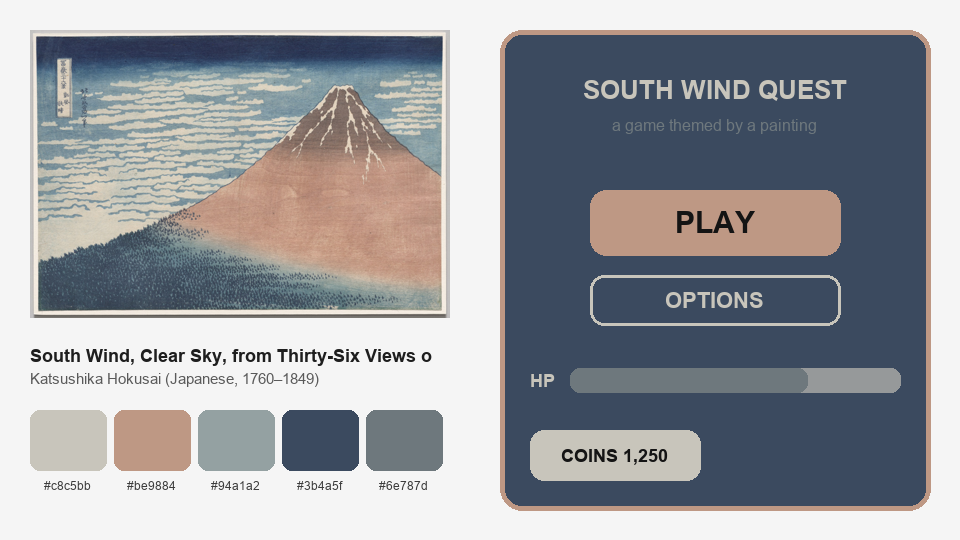

In [6]:
def get_font(size, bold=False):
    for name in (["arialbd.ttf", "DejaVuSans-Bold.ttf"] if bold else ["arial.ttf", "DejaVuSans.ttf"]):
        try:
            return ImageFont.truetype(name, size)
        except OSError:
            continue
    return ImageFont.load_default(size)


W, H = 960, 540
canvas = Image.new("RGB", (W, H), (245, 245, 245))
d = ImageDraw.Draw(canvas)

# left: the painting and its palette
art_img = img.copy()
art_img.thumbnail((420, 300))
canvas.paste(art_img, (30, 30))
d.text((30, 345), art["title"][:46], fill=(30, 30, 30), font=get_font(18, True))
d.text((30, 370), (art["artist"])[:46], fill=(90, 90, 90), font=get_font(15))
for i, c in enumerate(palette):
    x = 30 + i * 84
    d.rounded_rectangle((x, 410, x + 76, 470), radius=10, fill=c)
    d.text((x + 38, 486), "#%02x%02x%02x" % c, fill=(60, 60, 60), font=get_font(12), anchor="mm")

# right: mock game screen built only from the palette
d.rounded_rectangle((500, 30, 930, 510), radius=22, fill=dark, outline=accent, width=5)
short = art["title"].split(",")[0].split("(")[0].strip()[:16]                 # short title so it fits the panel
title = (short + " QUEST").upper()
d.text((715, 90), title, fill=light, font=get_font(26, True), anchor="mm")
d.text((715, 125), "a game themed by a painting", fill=accent2, font=get_font(16), anchor="mm")

d.rounded_rectangle((590, 190, 840, 255), radius=16, fill=accent)                   # PLAY button
d.text((715, 222), "PLAY", fill=text_on(accent), font=get_font(30, True), anchor="mm")
d.rounded_rectangle((590, 275, 840, 325), radius=14, outline=light, width=3)          # secondary button
d.text((715, 300), "OPTIONS", fill=light, font=get_font(22, True), anchor="mm")

d.text((530, 380), "HP", fill=light, font=get_font(18, True), anchor="lm")             # health bar
d.rounded_rectangle((570, 368, 900, 392), radius=10, fill=tuple(int(0.35 * a + 0.65 * b) for a, b in zip(dark, light)))
d.rounded_rectangle((570, 368, 570 + int(330 * 0.72), 392), radius=10, fill=accent2)

d.rounded_rectangle((530, 430, 700, 480), radius=14, fill=light)                      # coin chip
d.text((615, 455), "COINS 1,250", fill=text_on(light), font=get_font(18, True), anchor="mm")

canvas.save(OUT / "palette_demo.png")
display(canvas)

## What you just saw
- **Free service:** the Cleveland Museum of Art Open Access API gave us a CC0 artwork. No key, no login.
- **Machine learning:** K-means turned thousands of pixels into 5 representative colors, with no labels and no training data.
- **Our code:** roles and drawing are plain rules.

## From demo to the full lab
| Demo | Lab version |
|---|---|
| one painting, typed by hand | thousands of paintings in a table (palette features + style, period) |
| K-means only | + a **classifier** that learns *which palettes belong to which style or mood* |
| a PNG in the notebook | a **FastAPI** service: `GET /v1/artworks/{id}/palette.png`, `POST /v1/themes` |
| one mock screen | buttons, HUD and title screens for several themes |

## Try it
1. Change `QUERY` (for example `"sunflowers"`) and run again.
2. Change `K` to 3 or 8. What happens to the palette?
3. Change the role rules: choose the accent by **lowest** saturation. Is the screen still readable?
4. Make colors more vivid: for each group, use the most saturated real pixel instead of the average.